# Práctica: máscaras de segmentación aplicadas a stickers y pop-ups

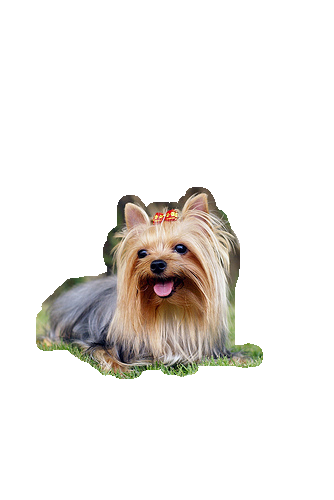

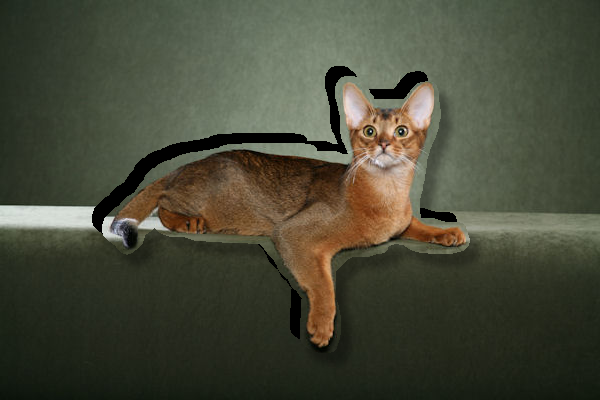

(c) MJMJ/2026

## 1. Cargar los datos
Ejecuta esta celda y selecciona `pets_toy.zip`.


In [ ]:
import io
import shutil
import zipfile
from pathlib import Path

import cv2
import numpy as np
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
if len(zip_names) != 1:
    raise ValueError("Selecciona un único ZIP del subconjunto.")

ROOT = Path("/content/pets_activity")
ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as archive:
    for member in archive.infolist():
        if not (ROOT / member.filename).resolve().is_relative_to(ROOT.resolve()):
            raise ValueError("Ruta no válida en el ZIP.")
    archive.extractall(ROOT)
del uploaded

IMAGES_DIR = ROOT / "pets_toy_set"
MASKS_DIR = ROOT / "pets_toy_set_annotations"
OUTPUT_DIR = Path("/content/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Función auxiliar de visualización: OpenCV lee BGR; el notebook muestra RGB.
def show_image(image_bgr):
    display(Image.fromarray(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)))


Saving pets_toy.zip to pets_toy.zip


In [1]:
# Para uso local

import io
import shutil
import zipfile
from pathlib import Path

import cv2
import numpy as np
from IPython.display import display
from PIL import Image


# Función auxiliar de visualización: OpenCV lee BGR; el notebook muestra RGB.
def show_image(image_bgr):
    display(Image.fromarray(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)))

## 2. Leer las parejas imagen–trimap
Busca los JPG y empareja cada uno con el PNG del mismo nombre base. Comprueba la lectura y que sus dimensiones coinciden.

**Pistas:** `Path.glob`, `Path.stem`, `cv2.imread`, `cv2.IMREAD_COLOR`, `cv2.IMREAD_GRAYSCALE`, `.shape`.


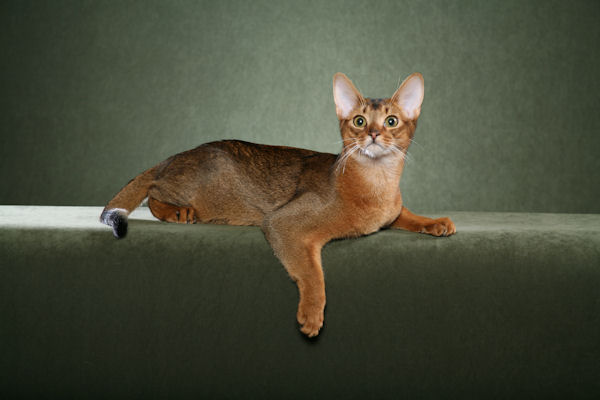

In [2]:
def read_pair(image_path, masks_dir):
    # TODO: construir la ruta del PNG, leer imagen y trimap y comprobarlos.
    # Devolver: image (BGR), trimap (escala de grises).

    image_path = Path(image_path)
    mask_dir = Path(masks_dir)

    mask_path = mask_dir / f"{image_path.stem}.png"

    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image.shape[:2] != mask.shape[:2]:
        raise RuntimeError("Las dimensiones no coinciden.")
    return image, mask

# TODO: obtener una lista ordenada de imágenes.
image_paths = Path('./pets_toy/pets_toy_set/').glob("*.jpg")
image_paths = sorted(image_paths)

image, trimap = read_pair(image_paths[0], './pets_toy/pets_toy_set_annotations/')

# TODO: leer una pareja y mostrar la imagen con show_image.
show_image(image)


## 3. Construir la máscara binaria
El trimap contiene **1 = animal**, **2 = fondo**, **3 = contorno**. Para esta actividad, incluye **1 y 3** en el animal.

Construye una máscara `uint8`: animal = **255**, fondo = **0**. Comprueba las etiquetas del trimap y de la máscara resultante.

**Pistas:** `np.unique`, comparaciones, operador `|`, `np.where`, `.astype(np.uint8)`.


Trimap: 



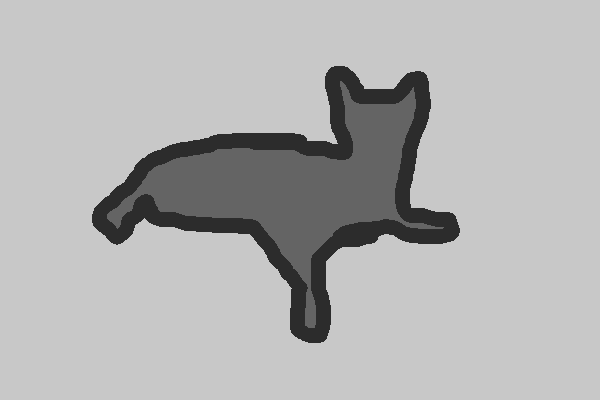

Máscara binaria: 



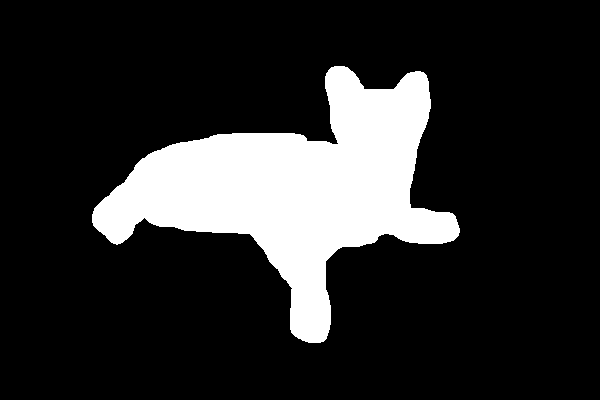

In [6]:
def make_mask(trimap):
    # TODO: convertir las etiquetas del trimap en una máscara binaria.
    binary_mask = np.where(((trimap == 1) | (trimap == 3)), 255, 0).astype(np.uint8)
    return binary_mask

# TODO: mostrar un trimap y su máscara binaria.
print("Trimap: \n")
display(Image.fromarray(trimap * 100, mode="L"))
print("Máscara binaria: \n")
binary_mask = make_mask(trimap=trimap)
display(Image.fromarray(binary_mask))

# Para visualizar una imagen de un canal, puedes usar display(Image.fromarray(...)).


## 4. Crear stickers sobre blanco
Conserva los píxeles del animal y convierte el resto en blanco (**255 en los tres canales**). Muestra **nueve parejas original–sticker**.

**Pistas:** `cv2.bitwise_and`, indexación booleana, `np.hstack`, `np.vstack`, `show_image`. Para unir imágenes de tamaños distintos, usa `cv2.resize`.


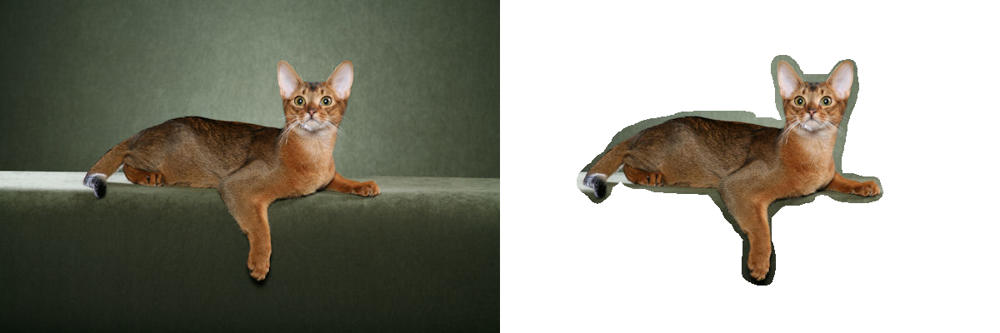

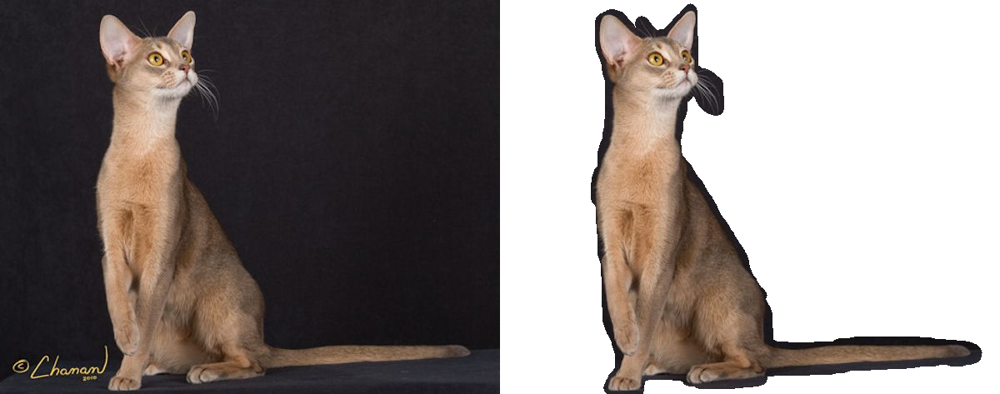

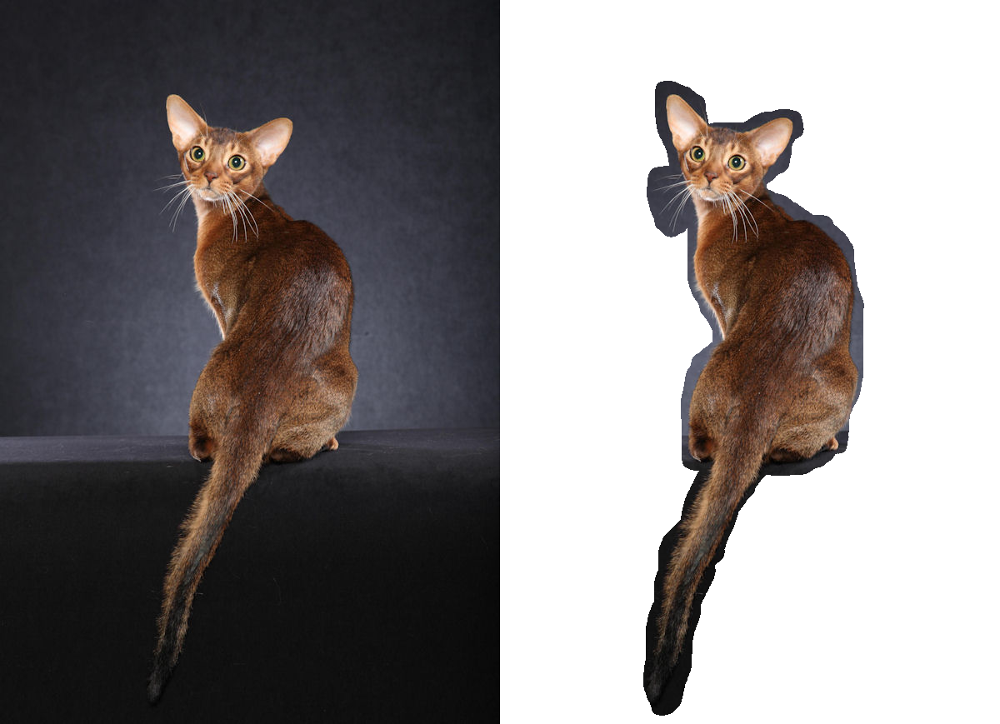

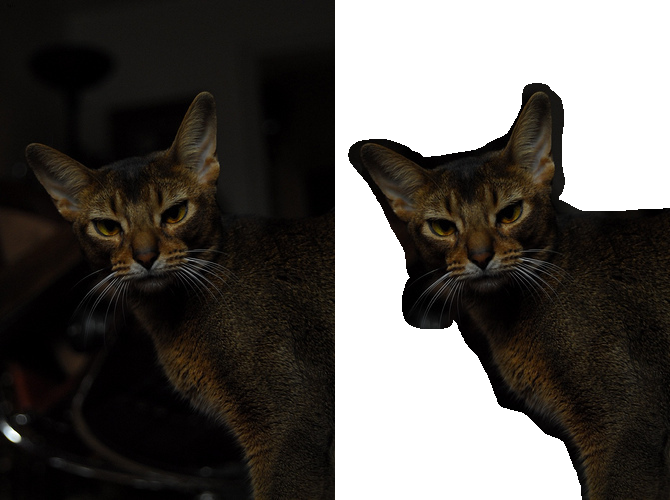

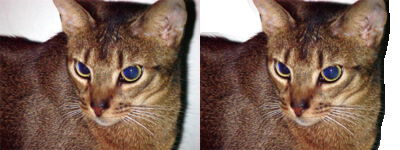

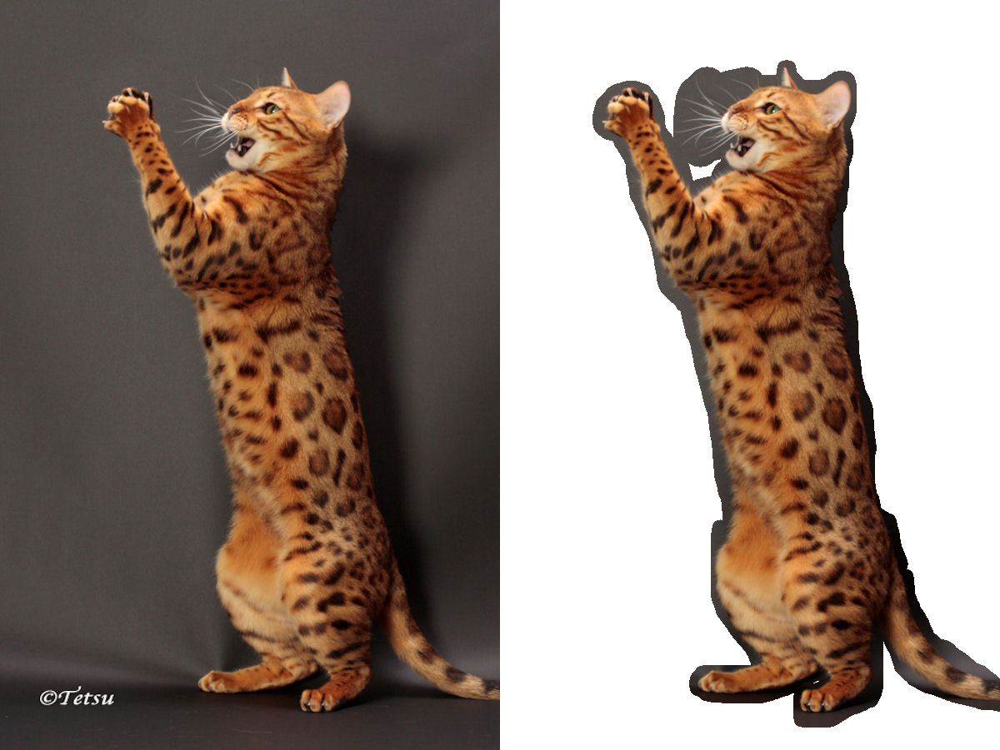

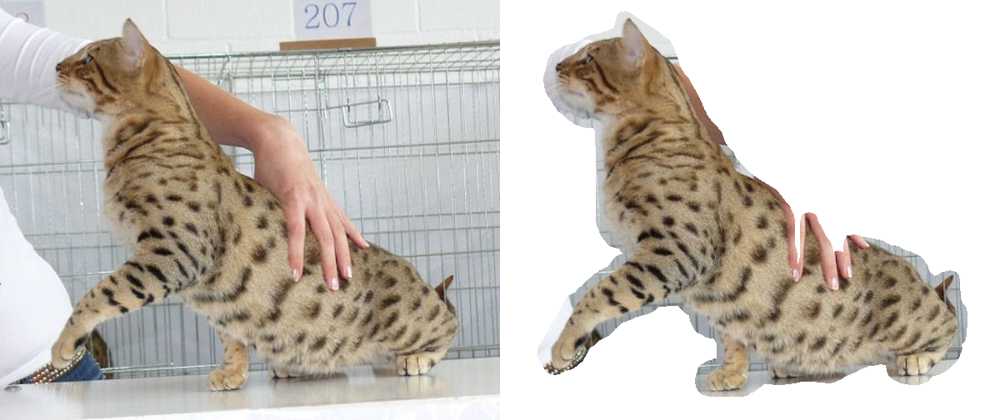

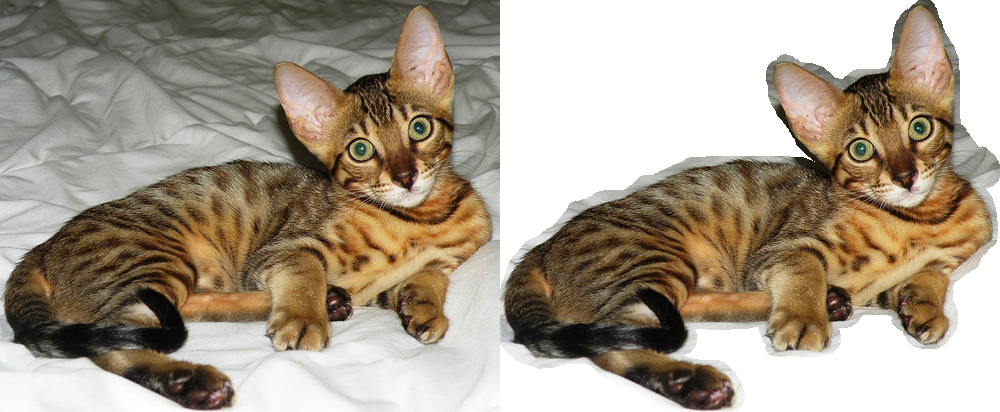

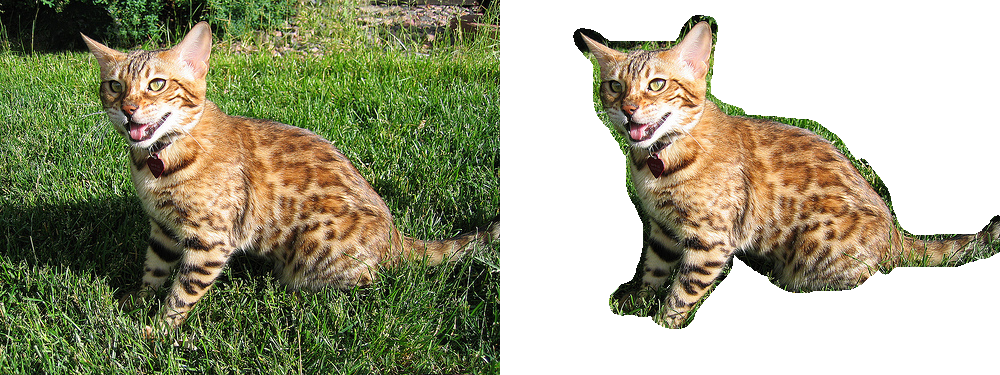

In [ ]:
def make_sticker(image, mask):
    # TODO: extraer el animal y poner a blanco el fondo.
    sticker = image.copy()
    sticker[mask == 0] = 255
    return sticker

# TODO: seleccionar nueve imágenes, crear sus stickers y mostrar las parejas.
for i in image_paths[:9]: # type: ignore
    image, trimap = read_pair(i, './pets_toy/pets_toy_set_annotations/')
    mask = make_mask(trimap=trimap)
    sticker = make_sticker(image=image, mask=mask)

    pair = np.hstack([image, sticker]) # type: ignore
    show_image(pair)


## 5. Desplazar el animal: pop-up
Elimina el animal de la imagen original dejando **un hueco negro**. Traslada el animal y su máscara con la misma matriz y pega el animal desplazado sobre ese fondo.

Usa **vecino más cercano para la máscara**. Conserva el tamaño del lienzo; lo que salga de sus límites se recorta.

`DX` y `DY` se expresan en píxeles. Positivo: derecha y abajo. Cambia los controles y vuelve a ejecutar la celda que genera los resultados.

**Pistas:** `cv2.bitwise_not`, `cv2.bitwise_and`, `np.float32`, `cv2.warpAffine`, `cv2.INTER_NEAREST`, indexación booleana. La matriz de traslación tiene filas `[1, 0, DX]` y `[0, 1, DY]`.


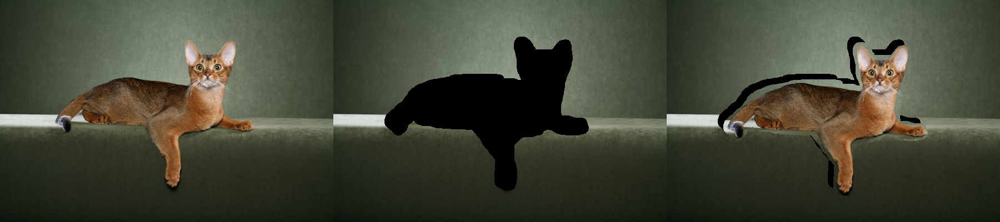

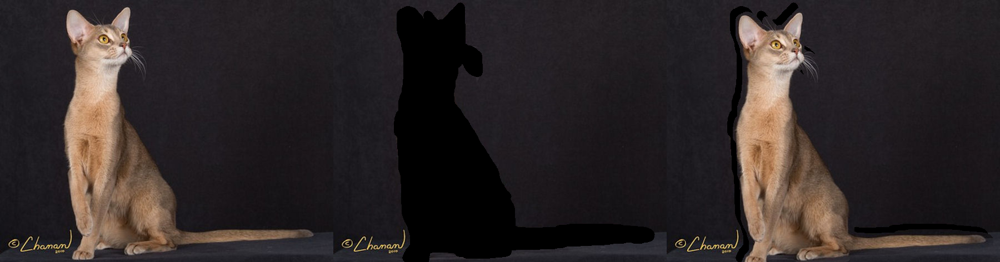

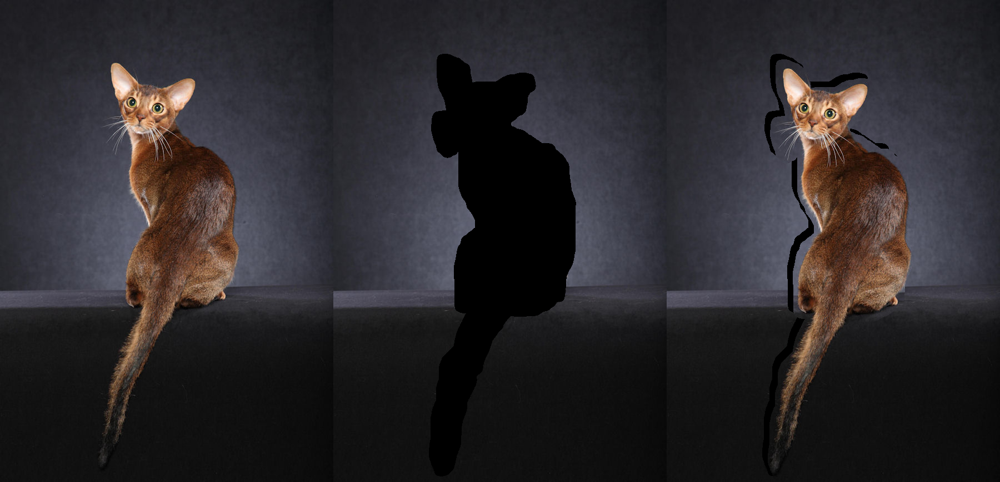

In [ ]:
DX = 10 #@param {type:"integer"}
DY = 10 #@param {type:"integer"}

def make_popup(image, mask, dx, dy):
    # TODO: crear el fondo con hueco negro.
    background = image.copy()
    background[mask == 255] = 0
    # TODO: trasladar el animal y su máscara.
    matrix = np.float32([[1,0,dx], [0,1,dy]]) # type: ignore
    h,w = image.shape[:2]
    sticker = make_sticker(image=image, mask=mask)
    # Desplazar el sticker y la máscara DX y DY píxeles
    shifted_sticker= cv2.warpAffine(src=sticker, M=matrix, dsize=(w, h)) # type: ignore
    shifted_mask = cv2.warpAffine(src=mask,M=matrix, dsize=(w, h), flags=cv2.INTER_NEAREST) # type: ignore

    # TODO: copiar solo los píxeles seleccionados por la máscara desplazada.
    # Devolver: background, shifted_mask, result.
    result = background.copy()
    result[shifted_mask == 255] = shifted_sticker[shifted_mask == 255]


    return background,shifted_mask, result

# TODO: mostrar tres comparaciones original–fondo con hueco–pop-up.
for img_path in image_paths[:3]: # type: ignore
    img, trimap = read_pair(img_path, './pets_toy/pets_toy_set_annotations/')
    mask = make_mask(trimap)
    bg, shifted_mask, popup = make_popup(img, mask, dx=DX, dy=DY)
    row = np.hstack([img, bg, popup]) # type: ignore
    show_image(row)


## 6. Añadir sombra (OPCIONAL)
Desplaza ligeramente una copia de la máscara del animal trasladado, suavízala y úsala para oscurecer el fondo. Pega el animal después de aplicar la sombra.

**Pistas:** `cv2.warpAffine`, `cv2.GaussianBlur`, `.astype(np.float32)`, división entre `255`, `[..., None]`, `np.clip`.


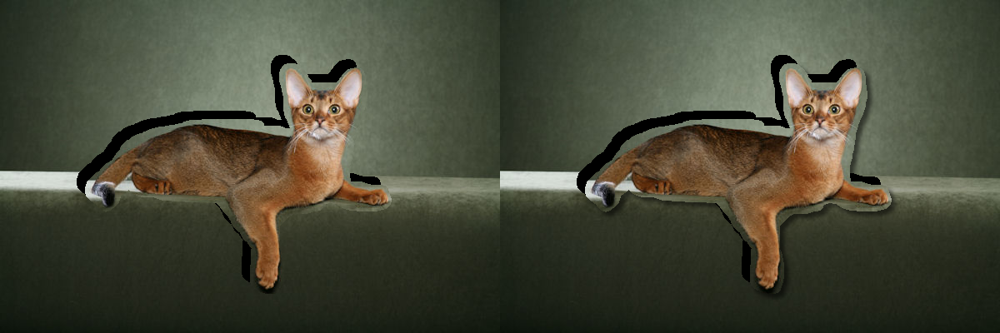

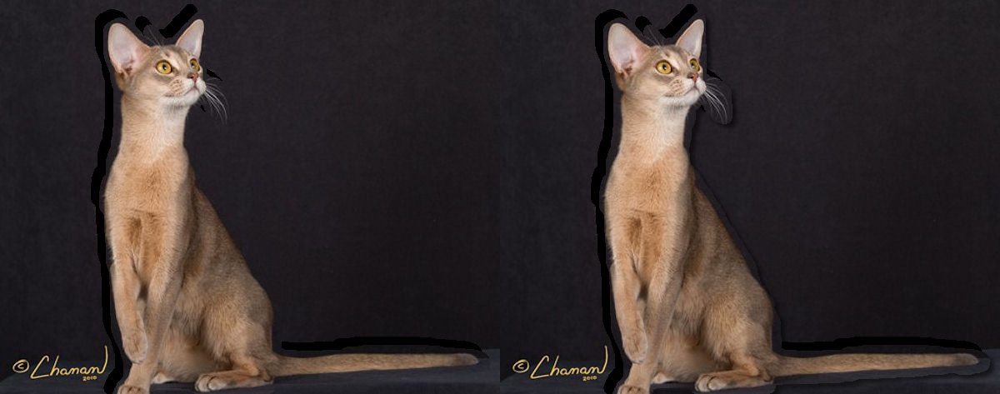

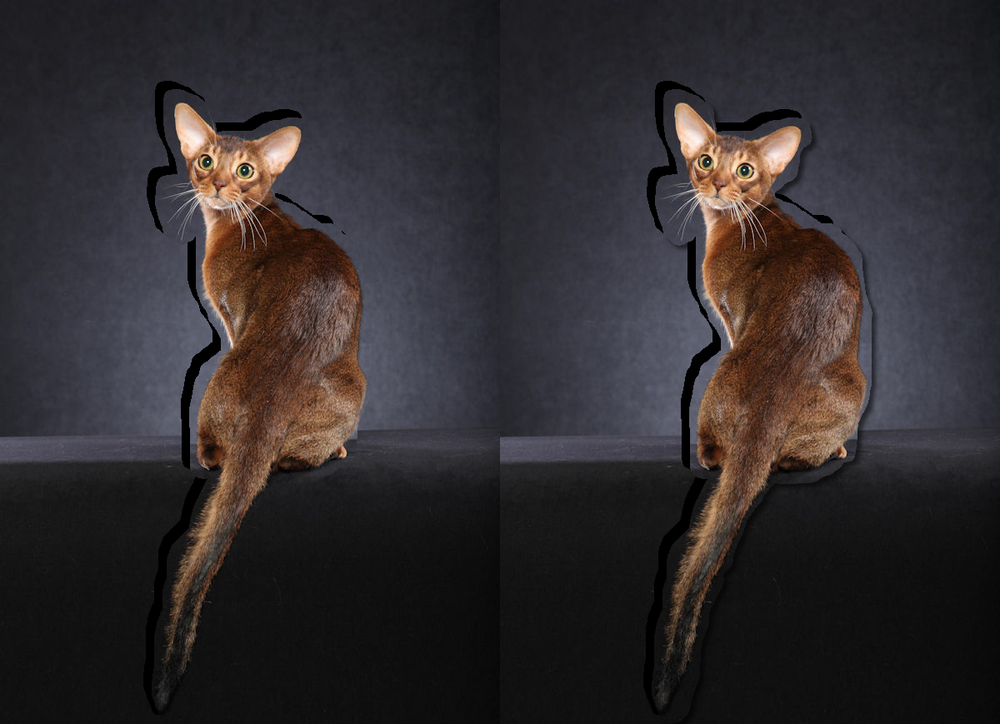

In [19]:
SHADOW_OPACITY = 0.55 #@param {type:"slider", min:0, max:1, step:0.05}

def add_shadow(background, shifted_mask, opacity):
    # TODO: desplazar y suavizar la máscara de sombra.+
    h, w = background.shape[:2]
    matrix = np.float32([[1, 0, 5], [0, 1, 5]]) # type: ignore
    shadow_mask = cv2.warpAffine(shifted_mask, matrix, (w, h), flags=cv2.INTER_NEAREST) # type: ignore
    blurred_shadow = cv2.GaussianBlur(shadow_mask.astype(np.float32), (15, 15), sigmaX=0)
    # TODO: oscurecer el fondo proporcionalmente a la sombra y la opacidad.
    shadow_factor = (blurred_shadow / 255.0) * opacity
    shadow_factor = shadow_factor[..., None]
    # Devolver el fondo sombreado; el animal se pega después.
    shaded_background = background.astype(np.float32) * (1.0 - shadow_factor)
    shaded_background = np.clip(shaded_background, 0, 255).astype(np.uint8)
    return shaded_background

# TODO: incorporar la sombra a la composición y mostrar el resultado.
for img_path in image_paths[:3]: # type: ignore
    img, trimap = read_pair(img_path, './pets_toy/pets_toy_set_annotations/')
    mask = make_mask(trimap)
    
    bg, shifted_mask, popup_no_shadow = make_popup(img, mask, dx=DX, dy=DY)
    
    h, w = img.shape[:2] # type: ignore
    M = np.float32([[1, 0, DX], [0, 1, DY]]) # type: ignore
    shifted_animal = cv2.warpAffine(img, M, (w, h)) # type: ignore
  
    shaded_bg = add_shadow(bg, shifted_mask, SHADOW_OPACITY)
    
    final_result = shaded_bg.copy()
    final_result[shifted_mask == 255] = shifted_animal[shifted_mask == 255]
    show_image(np.hstack([popup_no_shadow, final_result]))


## 7. Guardar los resultados
Guarda los stickers, la visualización de nueve parejas y tres composiciones pop-up en `OUTPUT_DIR`.

**Pistas:** `cv2.imwrite`, `Path.mkdir`. Ejecuta la última celda para descargar los resultados.


In [22]:
# TODO: guardar los resultados en OUTPUT_DIR.
OUTPUT_DIR = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for img_path in image_paths[:9]: # type: ignore
    img, trimap = read_pair(img_path, './pets_toy/pets_toy_set_annotations/')
    mask = make_mask(trimap)
    sticker = make_sticker(img, mask)

    cv2.imwrite(str(OUTPUT_DIR / f"sticker_{img_path.stem}.png"), sticker)

    pair = np.hstack([img, sticker]) # type: ignore
    cv2.imwrite(str(OUTPUT_DIR / f"pair_{img_path.stem}.png"), pair)

for img_path in image_paths[:3]: # type: ignore
    img, trimap = read_pair(img_path, './pets_toy/pets_toy_set_annotations/')
    mask = make_mask(trimap)
    
    bg, shifted_mask, popup = make_popup(img, mask, dx=DX, dy=DY)
    
    h, w = img.shape[:2] # type: ignore
    M = np.float32([[1, 0, DX], [0, 1, DY]]) # type: ignore
    shifted_animal = cv2.warpAffine(img, M, (w, h)) # type: ignore
    shaded_bg = add_shadow(bg, shifted_mask, SHADOW_OPACITY)
    popup_shadow = shaded_bg.copy()
    popup_shadow[shifted_mask == 255] = shifted_animal[shifted_mask == 255]

    cv2.imwrite(str(OUTPUT_DIR / f"popup_{img_path.stem}.png"), popup)
    cv2.imwrite(str(OUTPUT_DIR / f"popup_shadow_{img_path.stem}.png"), popup_shadow)

print(f"Resultados guardados correctamente en: {OUTPUT_DIR}")

Resultados guardados correctamente en: results


In [ ]:
archive_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
files.download(archive_path)
